## 0. Configuração

In [1]:
# Aqui eu conecto o Colab ao meu Google Drive, para conseguir ler e salvar os arquivos do projeto
from google.colab import drive
drive.mount('/content/drive')

# Defino a pasta principal do projeto e crio as subpastas que vou usar ao longo do trabalho
import os
PASTA = '/content/drive/MyDrive/PI5_phishing'
for sub in ['dados/brutos', 'dados/processados', 'dados/urls_brasileiras', 'figuras', 'artigo']:
    os.makedirs(os.path.join(PASTA, sub), exist_ok=True)

print('Pastas prontas em', PASTA)


Mounted at /content/drive
Pastas prontas em /content/drive/MyDrive/PI5_phishing


##1. Carregamento

In [2]:
# baixo a base phiusiil direto do repositório uci, pra deixar registrada a origem dos dados
import requests, zipfile, io

URL_UCI = 'https://archive.ics.uci.edu/static/public/967/phiusiil+phishing+url+dataset.zip'
CAMINHO_CSV = os.path.join(PASTA, 'dados/brutos/PhiUSIIL_Phishing_URL_Dataset.csv')

# se o arquivo já está no drive, não precisa baixar de novo
if os.path.exists(CAMINHO_CSV):
    print('base já está no drive, download não necessário')
else:
    resposta = requests.get(URL_UCI, timeout=300)
    # abro o zip baixado e extraio pra pasta de dados brutos
    with zipfile.ZipFile(io.BytesIO(resposta.content)) as arquivo_zip:
        arquivo_zip.extractall(os.path.join(PASTA, 'dados/brutos'))

# confiro o que tem na pasta
print(os.listdir(os.path.join(PASTA, 'dados/brutos')))

base já está no drive, download não necessário
['PhiUSIIL_Phishing_URL_Dataset.csv']


In [3]:
# Importo o pandas, que é a biblioteca que vou usar para trabalhar com a tabela de dados
import pandas as pd

# Monto o caminho até o arquivo da base PhiUSIIL, que salvei na pasta de dados brutos
CAMINHO_CSV = os.path.join(PASTA, 'dados/brutos/PhiUSIIL_Phishing_URL_Dataset.csv')

# Leio o CSV e guardo a tabela na variável df
df = pd.read_csv(CAMINHO_CSV)

# Confiro o tamanho da base: quantas linhas (URLs) e quantas colunas (variáveis)
print('Linhas e colunas:', df.shape)

# Mostro as 5 primeiras linhas para ver como os dados estão organizados
df.head()

Linhas e colunas: (235795, 56)


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [4]:
# Montando uma tabela resumo das colunas, para conhecer cada variável antes de tratar os dados
resumo = pd.DataFrame({
    'tipo': df.dtypes,                      # se a coluna é número ou texto
    'valores_unicos': df.nunique(),         # quantos valores diferentes ela tem
    'faltantes': df.isnull().sum()          # quantos valores estão vazios
})

# Mostro todas as linhas da tabela, sem cortar no meio
pd.set_option('display.max_rows', 60)
resumo

,tipo,valores_unicos,faltantes
FILENAME,object,235795,0
URL,object,235370,0
URLLength,int64,482,0
Domain,object,220086,0
DomainLength,int64,101,0
IsDomainIP,int64,2,0
TLD,object,695,0
URLSimilarityIndex,float64,36360,0
CharContinuationRate,float64,898,0
TLDLegitimateProb,float64,465,0


##2. Pré-processamento

In [5]:
# Separo as colunas em grupos. Essa divisão é a base do experimento:
# o Cenário A usa URL + conteúdo e o Cenário B usa só a URL

# Colunas que só identificam o site e não entram no modelo
colunas_id = ['FILENAME', 'URL', 'Domain']

# Colunas de texto que vou retirar (a informação delas já aparece em outras colunas numéricas)
colunas_texto = ['TLD', 'Title']

# Variáveis calculadas só a partir do endereço (sem abrir a página)
variaveis_url = ['URLLength', 'DomainLength', 'IsDomainIP', 'URLSimilarityIndex',
                 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength',
                 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio',
                 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL',
                 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL',
                 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS']

# Variáveis que dependem de abrir a página e ler o código dela
variaveis_conteudo = ['LineOfCode', 'LargestLineLength', 'HasTitle', 'DomainTitleMatchScore',
                      'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive',
                      'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup',
                      'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton',
                      'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto',
                      'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef',
                      'NoOfEmptyRef', 'NoOfExternalRef']

# Variável que o modelo vai aprender a prever (1 = legítima, 0 = phishing)
alvo = 'label'

# Confiro se a soma dos grupos bate com o total de colunas da base, para garantir que não esqueci nenhuma
total = len(colunas_id) + len(colunas_texto) + len(variaveis_url) + len(variaveis_conteudo) + 1
print('Variáveis da URL:', len(variaveis_url))
print('Variáveis do conteúdo:', len(variaveis_conteudo))
print('Total conferido:', total, 'de', df.shape[1], 'colunas')

Variáveis da URL: 22
Variáveis do conteúdo: 28
Total conferido: 56 de 56 colunas


In [6]:
# Investigando as URLs que aparecem mais de uma vez na base, antes de decidir o que fazer com elas
duplicadas = df[df.duplicated(subset='URL', keep=False)]

print('Linhas com URL repetida:', len(duplicadas))
print('URLs diferentes entre elas:', duplicadas['URL'].nunique())

# Verificando se alguma URL repetida aparece com rótulos diferentes (legítima numa linha e phishing em outra)
rotulos_por_url = duplicadas.groupby('URL')[alvo].nunique()
conflitos = rotulos_por_url[rotulos_por_url > 1]
print('URLs com rótulos conflitantes:', len(conflitos))

# Exibindo alguns exemplos para entender como são essas repetições
duplicadas.sort_values('URL')[['URL', alvo]].head(10)

Linhas com URL repetida: 850
URLs diferentes entre elas: 425
URLs com rótulos conflitantes: 0


,URL,label
219489,http://2f3a.reicrut-chat.workers.dev/,0
57609,http://2f3a.reicrut-chat.workers.dev/,0
227564,http://34.149.138.117/,0
27166,http://34.149.138.117/,0
147448,http://595221.selcdn.ru/qwerty-ohdhdjejnnad-na...,0
189978,http://595221.selcdn.ru/qwerty-ohdhdjejnnad-na...,0
57315,http://595221.selcdn.ru/qwerty-ohdhdjejnnad-na...,0
31955,http://595221.selcdn.ru/qwerty-ohdhdjejnnad-na...,0
197956,http://91.239.125.28/postchs/sms.php,0
126246,http://91.239.125.28/postchs/sms.php,0


### Tratamento das URLs duplicadas

Na verificação anterior, apareceram 425 URLs que se repetem na base, cada uma exatamente duas vezes, somando 850 linhas. Nenhuma delas tem rótulos conflitantes: a mesma URL nunca aparece como legítima em uma linha e como phishing em outra. Ou seja, são cópias idênticas.

Todas as repetições observadas são de phishing, o que faz sentido, já que listas de denúncia costumam registrar o mesmo link malicioso mais de uma vez.

**Decisão:** remover as cópias, mantendo apenas uma linha de cada URL.

**Por quê:** se a mesma URL ficar duplicada, uma cópia pode cair no conjunto de treino e a outra no de teste. Nesse caso, o modelo seria avaliado em um exemplo que já viu, o que deixaria o desempenho artificialmente melhor. Remover as cópias garante uma avaliação mais honesta.

In [7]:
# Removendo as URLs duplicadas, mantendo apenas a primeira ocorrência de cada uma.
# Como não há conflito de rótulo, as cópias são idênticas e podem sair sem perda de informação.
# Isso também evita que a mesma URL apareça no treino e no teste ao mesmo tempo.
linhas_antes = len(df)
df = df.drop_duplicates(subset='URL', keep='first').reset_index(drop=True)

print('Linhas antes:', linhas_antes)
print('Linhas removidas:', linhas_antes - len(df))
print('Linhas depois:', len(df))

# Conferindo como ficou a proporção entre sites legítimos (1) e phishing (0) depois da limpeza
print('\nDistribuição das classes:')
print(df[alvo].value_counts())
print(df[alvo].value_counts(normalize=True).round(4) * 100)

Linhas antes: 235795
Linhas removidas: 425
Linhas depois: 235370

Distribuição das classes:
label
1    134850
0    100520
Name: count, dtype: int64
label
1    57.29
0    42.71
Name: proportion, dtype: float64


### Remoção das colunas de identificação e de texto

Algumas colunas da base não entram nos modelos:

- **FILENAME, URL e Domain** apenas identificam cada site. Elas são únicas (ou quase únicas) para cada linha, então o modelo não aprenderia padrões com elas, só decoraria exemplos.
- **TLD** (extensão do domínio, como .com ou .br) tem 695 valores diferentes. Transformar isso em colunas criaria centenas de variáveis novas. A informação dela já aparece de forma numérica em **TLDLegitimateProb** e **TLDLength**.
- **Title** (título da página) é texto livre. A informação útil dele já está em **HasTitle**, **DomainTitleMatchScore** e **URLTitleMatchScore**.

A coluna **URL** é mantida em um arquivo separado, para consulta, caso seja preciso olhar algum exemplo específico durante a análise.

In [8]:
# Montando a base que vai para os modelos: só as variáveis numéricas (URL + conteúdo) e o alvo
df_modelo = df[variaveis_url + variaveis_conteudo + [alvo]].copy()

print('Base para modelagem:', df_modelo.shape)

# Conferindo se todas as colunas restantes são numéricas, já que os algoritmos só trabalham com números
nao_numericas = df_modelo.select_dtypes(exclude='number').columns.tolist()
print('Colunas não numéricas:', nao_numericas if nao_numericas else 'nenhuma')

# Salvando a base tratada na pasta de dados processados, para não precisar refazer a limpeza nas próximas sessões
df_modelo.to_csv(os.path.join(PASTA, 'dados/processados/base_modelo.csv'), index=False)

# Salvando à parte a URL junto com o rótulo, para consulta de exemplos durante a análise
df[['URL', alvo]].to_csv(os.path.join(PASTA, 'dados/processados/urls_referencia.csv'), index=False)

print('Arquivos salvos em dados/processados')

Base para modelagem: (235370, 51)
Colunas não numéricas: nenhuma
Arquivos salvos em dados/processados


### Resumo do pré-processamento

Ao final desta etapa, a base ficou assim:

| Etapa | Resultado |
|---|---|
| Base original | 235.795 linhas e 56 colunas |
| URLs duplicadas removidas | 425 linhas (cópias idênticas, sem conflito de rótulo) |
| Colunas retiradas | 5 (FILENAME, URL, Domain, TLD e Title) |
| **Base final para modelagem** | **235.370 linhas e 51 colunas** |

As 51 colunas da base final estão divididas em:

- **22 variáveis da URL**, calculadas só a partir do endereço, usadas nos Cenários A e B;
- **28 variáveis do conteúdo da página**, usadas só no Cenário A;
- **1 variável alvo** (label: 1 = legítima, 0 = phishing).

Todas as variáveis são numéricas e não há valores faltantes. A proporção entre as classes se manteve praticamente igual à original: **57,29% legítimas** (134.850) e **42,71% phishing** (100.520).

Foram salvos dois arquivos na pasta `dados/processados`:

- `base_modelo.csv`: a base pronta para a análise exploratória e a modelagem;
- `urls_referencia.csv`: as URLs com seus rótulos, para consulta de exemplos durante a análise.

##3. Análise exploratória

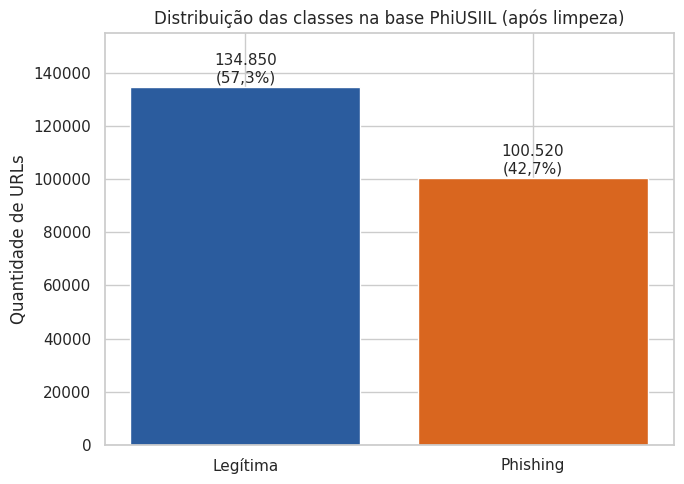

In [9]:
# Importando as bibliotecas de gráficos
import matplotlib.pyplot as plt
import seaborn as sns

# Definindo um estilo padrão para os gráficos do projeto
sns.set_theme(style='whitegrid')
CORES = {1: '#2B5C9E', 0: '#D9661F'}   # azul para legítimas, laranja para phishing
NOMES = {1: 'Legítima', 0: 'Phishing'}

# Contando quantas URLs há em cada classe
contagem = df_modelo[alvo].value_counts().sort_index(ascending=False)

# Gráfico de barras da distribuição das classes
fig, ax = plt.subplots(figsize=(7, 5))
barras = ax.bar([NOMES[c] for c in contagem.index], contagem.values,
                color=[CORES[c] for c in contagem.index])

# Quantidade e porcentagem em cima de cada barra, no formato brasileiro
for barra, valor in zip(barras, contagem.values):
    pct = valor / contagem.sum() * 100
    quantidade_txt = f'{valor:,}'.replace(',', '.')        # 134850 -> 134.850
    pct_txt = f'{pct:.1f}'.replace('.', ',')                # 57.3 -> 57,3
    ax.text(barra.get_x() + barra.get_width() / 2, valor + 1500,
            quantidade_txt + '\n(' + pct_txt + '%)', ha='center', fontsize=11)
ax.set_title('Distribuição das classes na base PhiUSIIL (após limpeza)')
ax.set_ylabel('Quantidade de URLs')
ax.set_ylim(0, contagem.max() * 1.15)

# Salvando o gráfico na pasta de figuras
plt.tight_layout()
plt.savefig(os.path.join(PASTA, 'figuras/01_distribuicao_classes.png'), dpi=300)
plt.show()

### Tradução dos nomes das variáveis

Os nomes originais das variáveis da base PhiUSIIL estão em inglês e seguem a nomenclatura técnica dos autores, como NoOfOtherSpecialCharsInURL e DegitRatioInURL, o que dificulta a leitura dos resultados. Para facilitar a interpretação, os gráficos e tabelas passam a apresentar os nomes traduzidos para o português.

Os nomes originais são mantidos no código, pois correspondem às colunas da base. A correspondência entre os nomes originais e os traduzidos é definida a seguir e também apresentada no dicionário de variáveis do trabalho.

In [10]:
# tradução dos nomes das variáveis da url pra usar nos gráficos e tabelas do trabalho
# (inclui as que saem depois na eda, porque elas aparecem no mapa de calor)
NOMES_PT = {
    'URLLength': 'Tamanho da URL',
    'DomainLength': 'Tamanho do domínio',
    'IsDomainIP': 'Domínio é um IP',
    'CharContinuationRate': 'Continuidade de caracteres',
    'TLDLength': 'Tamanho da extensão (TLD)',
    'NoOfSubDomain': 'Qtd. de subdomínios',
    'HasObfuscation': 'Possui ofuscação',
    'NoOfObfuscatedChar': 'Qtd. de caracteres ofuscados',
    'ObfuscationRatio': 'Proporção de ofuscação',
    'NoOfLettersInURL': 'Qtd. de letras',
    'LetterRatioInURL': 'Proporção de letras',
    'NoOfDegitsInURL': 'Qtd. de dígitos',
    'DegitRatioInURL': 'Proporção de dígitos',
    'NoOfEqualsInURL': 'Qtd. de "="',
    'NoOfQMarkInURL': 'Qtd. de "?"',
    'NoOfAmpersandInURL': 'Qtd. de "&"',
    'NoOfOtherSpecialCharsInURL': 'Qtd. de caracteres especiais',
    'SpacialCharRatioInURL': 'Proporção de caracteres especiais',
    'IsHTTPS': 'Usa HTTPS',
}
print('nomes traduzidos:', len(NOMES_PT))

nomes traduzidos: 19


In [11]:
# acrescentando as variáveis do conteúdo e as três que saem no começo da eda,
# pra traduzir também a tabela de auc
NOMES_PT.update({
    'URLSimilarityIndex': 'Índice de similaridade da URL',
    'TLDLegitimateProb': 'Prob. de extensão legítima',
    'URLCharProb': 'Prob. dos caracteres da URL',
    'LineOfCode': 'Linhas de código',
    'LargestLineLength': 'Maior linha de código',
    'HasTitle': 'Possui título',
    'DomainTitleMatchScore': 'Semelhança domínio-título',
    'URLTitleMatchScore': 'Semelhança URL-título',
    'HasFavicon': 'Possui favicon',
    'Robots': 'Possui robots.txt',
    'IsResponsive': 'Página responsiva',
    'NoOfURLRedirect': 'Qtd. de redirecionamentos',
    'NoOfSelfRedirect': 'Qtd. de redirecionamentos internos',
    'HasDescription': 'Possui descrição',
    'NoOfPopup': 'Qtd. de pop-ups',
    'NoOfiFrame': 'Qtd. de iframes',
    'HasExternalFormSubmit': 'Formulário envia para outro site',
    'HasSocialNet': 'Links para redes sociais',
    'HasSubmitButton': 'Possui botão de envio',
    'HasHiddenFields': 'Possui campos ocultos',
    'HasPasswordField': 'Possui campo de senha',
    'Bank': 'Menciona banco',
    'Pay': 'Menciona pagamento',
    'Crypto': 'Menciona criptomoeda',
    'HasCopyrightInfo': 'Possui direitos autorais',
    'NoOfImage': 'Qtd. de imagens',
    'NoOfCSS': 'Qtd. de arquivos CSS',
    'NoOfJS': 'Qtd. de arquivos JavaScript',
    'NoOfSelfRef': 'Qtd. de links internos',
    'NoOfEmptyRef': 'Qtd. de links vazios',
    'NoOfExternalRef': 'Qtd. de links externos',
})
print('nomes traduzidos no total:', len(NOMES_PT))

nomes traduzidos no total: 50


### Poder de separação de cada variável

Antes de treinar o modelo, é importante saber se alguma variável, sozinha, já separa quase perfeitamente sites legítimos de phishing. Se isso acontecer, o modelo pode chegar perto de 100% de acerto só por causa dela, e o resultado não refletiria a realidade.

Para medir isso, foi calculada a **AUC** de cada variável isolada. A AUC vai de 0,5 a 1,0:
- **0,5:** a variável não ajuda em nada a separar as classes (equivale a chutar);
- **1,0:** a variável separa as classes perfeitamente.

Variáveis com AUC muito próxima de 1,0 são suspeitas e precisam ser investigadas.

In [12]:
# Importando a função que calcula a AUC
from sklearn.metrics import roc_auc_score

# Calculando, para cada variável o quanto ela sozinha consegue separar legítimas de phishing
auc = {}
for coluna in variaveis_url + variaveis_conteudo:
    valor = roc_auc_score(df_modelo[alvo], df_modelo[coluna])
    # Usando o maior valor entre a AUC e o seu inverso, porque aqui interessa o poder de separação,
    # não a direção (se valores altos indicam legítima ou phishing)
    auc[coluna] = max(valor, 1 - valor)

# Montando uma tabela com o resultado e indicando o grupo de cada variável
tabela_auc = pd.DataFrame({'AUC_sozinha': auc})
tabela_auc['grupo'] = ['URL' if c in variaveis_url else 'Conteúdo' for c in tabela_auc.index]

# coluna com o nome em português, ao lado do original
tabela_auc['variável (pt)'] = tabela_auc.index.map(NOMES_PT)

# Exibindo as 15 variáveis que mais separam as classes sozinhas
tabela_auc.sort_values('AUC_sozinha', ascending=False).round(4).head(15)

,AUC_sozinha,grupo,variável (pt)
URLSimilarityIndex,0.9961,URL,Índice de similaridade da URL
LineOfCode,0.9903,Conteúdo,Linhas de código
NoOfExternalRef,0.9880,Conteúdo,Qtd. de links externos
NoOfImage,0.9797,Conteúdo,Qtd. de imagens
NoOfSelfRef,0.9725,Conteúdo,Qtd. de links internos
NoOfJS,0.9709,Conteúdo,Qtd. de arquivos JavaScript
NoOfCSS,0.9577,Conteúdo,Qtd. de arquivos CSS
HasSocialNet,0.8947,Conteúdo,Links para redes sociais
HasCopyrightInfo,0.8755,Conteúdo,Possui direitos autorais
HasDescription,0.8463,Conteúdo,Possui descrição


### Decisão: retirada de variáveis derivadas pelos autores da base

A análise de AUC mostrou que **URLSimilarityIndex**, sozinha, separa quase perfeitamente as classes (AUC = 0,996). Segundo o artigo de origem da base (Prasad e Chandra, 2024), essa variável corresponde ao índice de similaridade de URL (USI), a técnica de detecção proposta pelos próprios autores. Mantê-la no modelo significaria, na prática, reaproveitar o detector deles, e não avaliar o que a Regressão Logística aprende a partir das características do endereço.

Além dela, **TLDLegitimateProb** e **URLCharProb** são, segundo a documentação da base, variáveis derivadas de outras informações, calculadas a partir das listas usadas pelos autores. Elas não podem ser recalculadas da mesma forma para URLs novas, o que impediria a validação com URLs brasileiras.

**Decisão:** retirar as três variáveis dos dois cenários. Com isso, o Cenário B passa a usar apenas características que podem ser calculadas diretamente a partir do endereço.

Também se observou que as variáveis do conteúdo da página (como LineOfCode, NoOfExternalRef e NoOfImage) têm AUC acima de 0,95. Nesse caso não se trata de vazamento: páginas de phishing costumam ser mais simples, com menos código, imagens e links. Essas variáveis permanecem no Cenário A.

In [13]:
# Retirando as variáveis derivadas pelos autores da base, que não podem ser reproduzidas em URLs novas
retiradas = ['URLSimilarityIndex', 'TLDLegitimateProb', 'URLCharProb']
variaveis_url = [v for v in variaveis_url if v not in retiradas]
df_modelo = df_modelo.drop(columns=retiradas, errors='ignore')

print('Variáveis da URL que ficam no modelo:', len(variaveis_url))
print('Variáveis do conteúdo:', len(variaveis_conteudo))
print('Base para modelagem:', df_modelo.shape)

# Conferindo o poder de separação das variáveis da URL que sobraram, que são a base do Cenário B
tabela_auc.loc[variaveis_url].sort_values('AUC_sozinha', ascending=False).round(4)

Variáveis da URL que ficam no modelo: 19
Variáveis do conteúdo: 28
Base para modelagem: (235370, 48)


,AUC_sozinha,grupo,variável (pt)
NoOfOtherSpecialCharsInURL,0.8232,URL,Qtd. de caracteres especiais
SpacialCharRatioInURL,0.8071,URL,Proporção de caracteres especiais
IsHTTPS,0.7544,URL,Usa HTTPS
CharContinuationRate,0.7435,URL,Continuidade de caracteres
NoOfLettersInURL,0.7416,URL,Qtd. de letras
URLLength,0.7317,URL,Tamanho da URL
NoOfDegitsInURL,0.7277,URL,Qtd. de dígitos
DegitRatioInURL,0.7258,URL,Proporção de dígitos
LetterRatioInURL,0.7146,URL,Proporção de letras
DomainLength,0.6240,URL,Tamanho do domínio


### Correlação entre as variáveis da URL

Algumas variáveis da URL parecem medir quase a mesma coisa, como o tamanho da URL e a quantidade de letras. Isso atrapalha a Regressão Logística, então aqui verifico quais variáveis estão muito correlacionadas (acima de 0,8) para decidir quais manter.

#### Variáveis da URL usadas nesta análise

| Variável | O que mede |
|---|---|
| URLLength | tamanho da URL (número de caracteres) |
| DomainLength | tamanho do domínio |
| IsDomainIP | se o domínio é um número de IP em vez de um nome (sim/não) |
| TLDLength | tamanho da extensão do domínio (.com, .br, .xyz) |
| NoOfSubDomain | quantidade de subdomínios |
| IsHTTPS | se a URL usa HTTPS (sim/não) |
| CharContinuationRate | quanto a URL tem sequências seguidas do mesmo tipo de caractere |
| NoOfLettersInURL / LetterRatioInURL | quantidade e proporção de letras |
| NoOfDegitsInURL / DegitRatioInURL | quantidade e proporção de dígitos |
| NoOfEqualsInURL | quantidade de sinais `=` |
| NoOfQMarkInURL | quantidade de `?` |
| NoOfAmpersandInURL | quantidade de `&` |
| NoOfOtherSpecialCharsInURL / SpacialCharRatioInURL | quantidade e proporção de outros caracteres especiais |
| HasObfuscation / NoOfObfuscatedChar / ObfuscationRatio | se há caracteres disfarçados (como `%20`), quantos e em que proporção |

Os nomes seguem a grafia original da base. A descrição completa de todas as variáveis está no dicionário de dados.

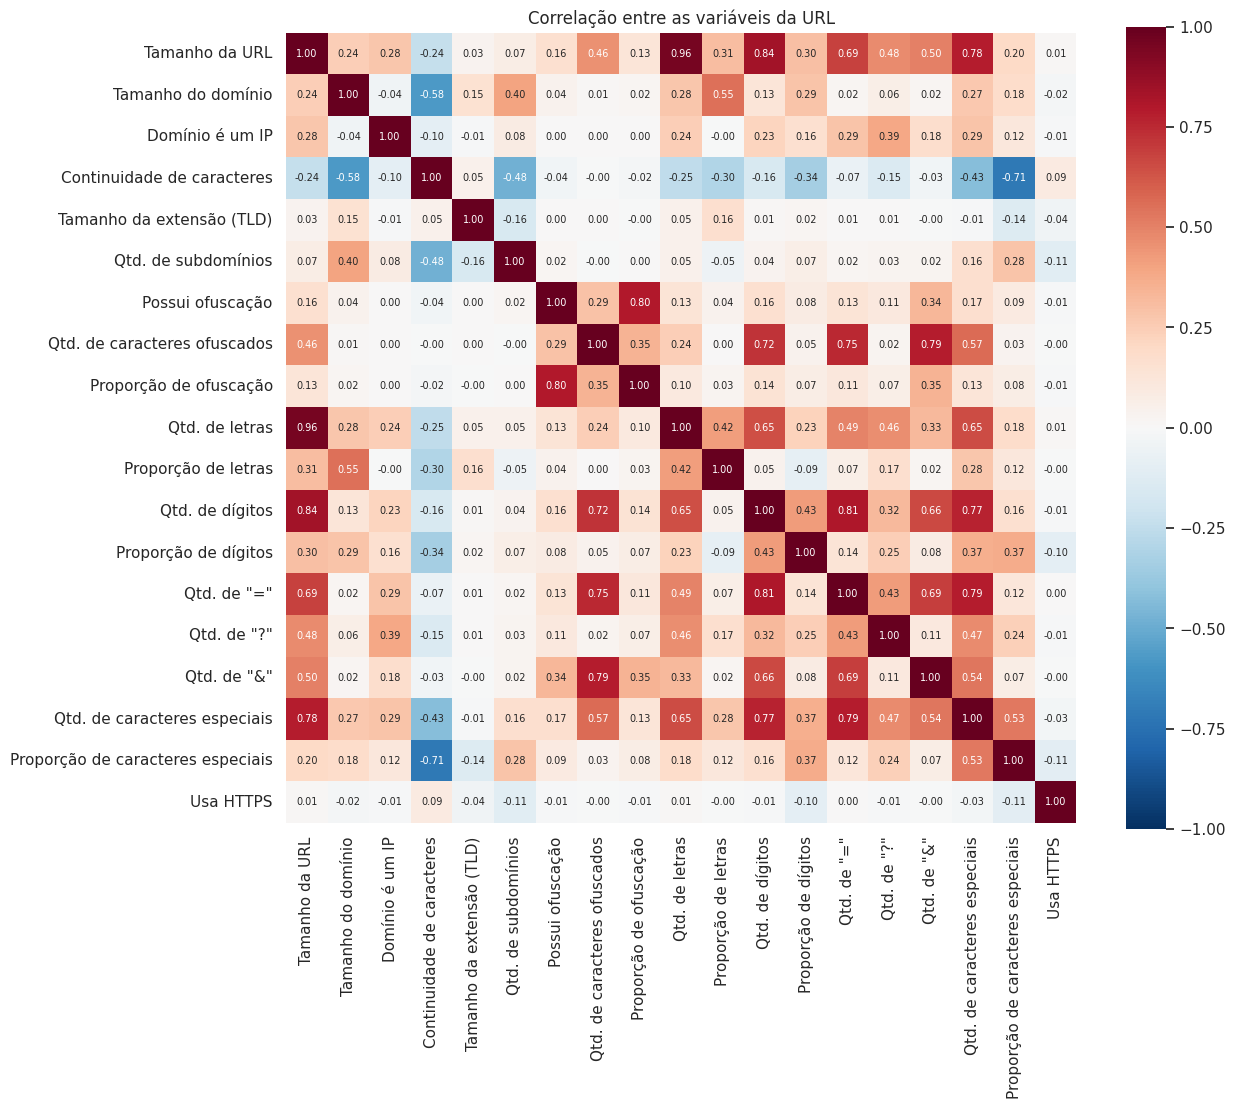

,variavel_1,variavel_2,correlacao
0,URLLength,NoOfLettersInURL,0.956
1,URLLength,NoOfDegitsInURL,0.836
2,NoOfDegitsInURL,NoOfEqualsInURL,0.806


In [14]:
# calculando a correlação entre todas as variáveis da url
correlacao = df_modelo[variaveis_url].corr()

# versão com os nomes em português, só pra desenhar o mapa
correlacao_pt = correlacao.rename(index=NOMES_PT, columns=NOMES_PT)

# desenhando o mapa de calor da correlação, pra ver quais variáveis andam juntas
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(correlacao_pt, cmap='RdBu_r', vmin=-1, vmax=1, center=0,
            annot=True, fmt='.2f', annot_kws={'size': 7}, square=True, ax=ax)
ax.set_title('Correlação entre as variáveis da URL')
plt.tight_layout()
plt.savefig(os.path.join(PASTA, 'figuras/02_correlacao_variaveis_url.png'), dpi=300)
plt.show()

# listando os pares com correlação forte (acima de 0,8), usando os nomes originais
pares = []
for i in range(len(variaveis_url)):
    for j in range(i + 1, len(variaveis_url)):
        valor = correlacao.iloc[i, j]
        if abs(valor) > 0.8:
            pares.append((variaveis_url[i], variaveis_url[j], round(valor, 3)))

pares_fortes = pd.DataFrame(pares, columns=['variavel_1', 'variavel_2', 'correlacao'])
pares_fortes.sort_values('correlacao', key=abs, ascending=False)

**O que o mapa responde:** quais variáveis da URL estão repetindo a mesma informação?

Cada quadrado mostra o quanto duas variáveis andam juntas. Quanto mais vermelho (perto de 1), mais elas sobem juntas; quanto mais azul (perto de -1), mais uma sobe enquanto a outra desce. Pares acima de 0,8 são considerados redundantes.

### Leitura do mapa de calor

Quanto mais vermelho, mais as duas variáveis sobem juntas; quanto mais azul, mais uma sobe enquanto a outra desce. Considerei redundantes os pares acima de 0,8:

| Par | Correlação | Por que andam juntas |
|---|---|---|
| URLLength e NoOfLettersInURL | 0,96 | URL mais longa tem mais letras |
| URLLength e NoOfDegitsInURL | 0,84 | URL mais longa também tende a ter mais dígitos |
| NoOfDegitsInURL e NoOfEqualsInURL | 0,81 | parâmetros como `?id=123` trazem dígitos e sinais de igual juntos |
| HasObfuscation e ObfuscationRatio | 0,80 (no limite) | as duas medem a ofuscação da URL |

De cada par, mantenho só uma variável. O par HasObfuscation e ObfuscationRatio ficou no limite (0,80 arredondado) e por isso não apareceu na lista do código, mas também foi tratado como redundante, pois as duas variáveis medem a mesma característica.

In [15]:
import numpy as np

# Retirando as variáveis redundantes da URL, identificadas no mapa de calor
redundantes = ['NoOfLettersInURL', 'NoOfDegitsInURL', 'ObfuscationRatio']
variaveis_url = [v for v in variaveis_url if v not in redundantes]
df_modelo = df_modelo.drop(columns=redundantes, errors='ignore')

print('Variáveis da URL no modelo:', len(variaveis_url))
print('Base para modelagem:', df_modelo.shape)

# Conferindo se ainda sobrou algum par acima de 0,8
correlacao_final = df_modelo[variaveis_url].corr().abs()
maior = correlacao_final.where(~np.eye(len(variaveis_url), dtype=bool)).max().max()
print('Maior correlação entre as variáveis restantes:', round(maior, 3))

Variáveis da URL no modelo: 16
Base para modelagem: (235370, 45)
Maior correlação entre as variáveis restantes: 0.786


In [16]:
# Calculando a correlação entre as variáveis do conteúdo
correlacao_conteudo = df_modelo[variaveis_conteudo].corr()

# Listando os pares acima de 0,8, do mesmo jeito que foi feito para a URL
pares = []
for i in range(len(variaveis_conteudo)):
    for j in range(i + 1, len(variaveis_conteudo)):
        valor = correlacao_conteudo.iloc[i, j]
        if abs(valor) > 0.8:
            pares.append((variaveis_conteudo[i], variaveis_conteudo[j], round(valor, 3)))

pares_conteudo = pd.DataFrame(pares, columns=['variavel_1', 'variavel_2', 'correlacao'])
print('Pares acima de 0,8:', len(pares_conteudo))
pares_conteudo.sort_values('correlacao', key=abs, ascending=False)

Pares acima de 0,8: 1


,variavel_1,variavel_2,correlacao
0,DomainTitleMatchScore,URLTitleMatchScore,0.961


In [17]:
# Retirando a variável redundante do conteúdo
variaveis_conteudo = [v for v in variaveis_conteudo if v != 'URLTitleMatchScore']
df_modelo = df_modelo.drop(columns=['URLTitleMatchScore'], errors='ignore')

print('Variáveis da URL:', len(variaveis_url))
print('Variáveis do conteúdo:', len(variaveis_conteudo))
print('Base final para modelagem:', df_modelo.shape)

# Salvando a base final, já sem as variáveis retiradas na análise exploratória
df_modelo.to_csv(os.path.join(PASTA, 'dados/processados/base_modelo_final.csv'), index=False)
print('Base final salva em dados/processados')

Variáveis da URL: 16
Variáveis do conteúdo: 27
Base final para modelagem: (235370, 44)
Base final salva em dados/processados


### Resumo da análise exploratória

- As classes estão relativamente equilibradas: 57,3% legítimas e 42,7% phishing.
- A URLSimilarityIndex separava as classes quase perfeitamente (AUC de 0,996), porque é a técnica de detecção dos próprios autores. Ela saiu, junto com TLDLegitimateProb e URLCharProb, que também não podem ser recalculadas para URLs novas.
- As variáveis do conteúdo são muito fortes (AUC acima de 0,95), o que explica o desempenho perto de 100% em outros estudos com essa base. As da URL ficam entre 0,5 e 0,82: nenhuma resolve sozinha, então o modelo vai precisar combinar várias.
- Retirei quatro variáveis redundantes (correlação acima de 0,8): NoOfLettersInURL, NoOfDegitsInURL, ObfuscationRatio e URLTitleMatchScore.

Base final: 235.370 URLs, 16 variáveis da URL (Cenários A e B) e 27 do conteúdo (só Cenário A).

Na sequência, as variáveis da URL foram recalculadas por função própria (seção seguinte), e duas novas redundâncias levaram o modelo a utilizar 14 variáveis da URL.


### Recálculo das variáveis da URL

Para garantir que o treinamento e o teste com URLs brasileiras utilizem exatamente a mesma regra de cálculo, as 16 variáveis da URL foram recalculadas por meio de função própria a partir do texto de cada endereço. A comparação com os valores originais, em uma amostra de 5.000 URLs, mostrou coincidência acima de 98% em 11 variáveis. As demais (tamanho da URL, proporção de letras, quantidade e proporção de caracteres especiais e taxa de continuidade) diferiram porque a base original desconsidera o protocolo e o prefixo "www" em parte dos cálculos e apresenta diferença de um caractere no tamanho de grande parte das URLs.

In [18]:
import re
import numpy as np
from urllib.parse import urlsplit

# padrão de um endereço ip (ex.: 34.149.138.117)
padrao_ip = re.compile(r'^\d{1,3}(\.\d{1,3}){3}$')

def maior_sequencia(texto, teste):
    # tamanho da maior sequência seguida de caracteres que passam no teste
    maior = atual = 0
    for c in texto:
        atual = atual + 1 if teste(c) else 0
        maior = max(maior, atual)
    return maior

def extrair_variaveis(url):
    url = str(url).strip()
    partes = urlsplit(url)                          # separa protocolo, domínio, caminho...
    dominio = (partes.hostname or '').lower()       # ex.: www.itau.com.br
    tld = dominio.rsplit('.', 1)[-1] if '.' in dominio else ''   # ex.: br

    tamanho = len(url)
    letras = sum(c.isascii() and c.isalpha() for c in url)
    digitos = sum(c.isdigit() for c in url)
    iguais = url.count('=')
    interrog = url.count('?')
    ecomercial = url.count('&')
    ofuscados = len(re.findall(r'%[0-9a-fA-F]{2}', url))   # tipo %20, %2F
    outros = sum((not c.isalnum()) and c not in '=?&' for c in url)

    # continuidade: maior sequência de letras + de dígitos + de símbolos, dividido pelo tamanho
    eh_letra = lambda c: c.isascii() and c.isalpha()
    eh_digito = lambda c: c.isdigit()
    eh_especial = lambda c: not c.isalnum()
    continuidade = (maior_sequencia(url, eh_letra) + maior_sequencia(url, eh_digito)
                    + maior_sequencia(url, eh_especial)) / tamanho if tamanho else 0

    return {
        'URLLength': tamanho,
        'DomainLength': len(dominio),
        'IsDomainIP': int(bool(padrao_ip.match(dominio))),
        'CharContinuationRate': continuidade,
        'TLDLength': len(tld),
        'NoOfSubDomain': max(dominio.count('.') - 1, 0),
        'HasObfuscation': int(ofuscados > 0),
        'NoOfObfuscatedChar': ofuscados,
        'LetterRatioInURL': letras / tamanho if tamanho else 0,
        'DegitRatioInURL': digitos / tamanho if tamanho else 0,
        'NoOfEqualsInURL': iguais,
        'NoOfQMarkInURL': interrog,
        'NoOfAmpersandInURL': ecomercial,
        'NoOfOtherSpecialCharsInURL': outros,
        'SpacialCharRatioInURL': outros / tamanho if tamanho else 0,
        'IsHTTPS': int(partes.scheme.lower() == 'https'),
    }

# teste rápido com uma url
extrair_variaveis('https://www.southbankmosaics.com')

{'URLLength': 32,
 'DomainLength': 24,
 'IsDomainIP': 0,
 'CharContinuationRate': 0.59375,
 'TLDLength': 3,
 'NoOfSubDomain': 1,
 'HasObfuscation': 0,
 'NoOfObfuscatedChar': 0,
 'LetterRatioInURL': 0.84375,
 'DegitRatioInURL': 0.0,
 'NoOfEqualsInURL': 0,
 'NoOfQMarkInURL': 0,
 'NoOfAmpersandInURL': 0,
 'NoOfOtherSpecialCharsInURL': 5,
 'SpacialCharRatioInURL': 0.15625,
 'IsHTTPS': 1}

In [19]:
# lista das 16 variáveis só pra validação (nome diferente pra não mexer na lista do modelo)
variaveis_validacao = ['URLLength', 'DomainLength', 'IsDomainIP', 'CharContinuationRate',
                       'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar',
                       'LetterRatioInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL',
                       'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL',
                       'IsHTTPS']

# juntando as urls com os valores originais da base (os dois arquivos estão na mesma ordem)
urls_ref = pd.read_csv(os.path.join(PASTA, 'dados/processados/urls_referencia.csv'))
base = pd.read_csv(os.path.join(PASTA, 'dados/processados/base_modelo.csv'))
base['URL'] = urls_ref['URL']

# sorteando 5.000 urls pra testar
amostra = base.sample(5000, random_state=42)

# calculando com a nossa função
calculadas = pd.DataFrame([extrair_variaveis(u) for u in amostra['URL']], index=amostra.index)

# comparando variável por variável
linhas = []
for v in variaveis_validacao:
    diferenca = calculadas[v] - amostra[v]
    tolerancia = 0.01 if amostra[v].dtype == float else 0   # proporções podem estar arredondadas
    iguais = (diferenca.abs() <= tolerancia).mean() * 100
    linhas.append({'variável': v,
                   '% igual à phiusiil': round(iguais, 1),
                   'diferença mais comum': diferenca.round(3).mode().iloc[0]})

validacao = pd.DataFrame(linhas).sort_values('% igual à phiusiil')
validacao

,variável,% igual à phiusiil,diferença mais comum
13,NoOfOtherSpecialCharsInURL,0.1,4.000
8,LetterRatioInURL,0.1,0.328
3,CharContinuationRate,0.5,-0.500
14,SpacialCharRatioInURL,0.7,0.136
0,URLLength,21.6,1.000
12,NoOfAmpersandInURL,98.6,0.000
9,DegitRatioInURL,99.3,0.000
7,NoOfObfuscatedChar,99.5,0.000
6,HasObfuscation,99.7,0.000
15,IsHTTPS,99.8,0.000


In [20]:
# colunas da base que ajudam a entender a contagem
# (as contagens brutas de letras e dígitos ainda estão no base_modelo.csv)
cols_base = ['URL', 'URLLength', 'NoOfLettersInURL', 'NoOfDegitsInURL',
             'NoOfOtherSpecialCharsInURL', 'CharContinuationRate']

exemplos = amostra[cols_base].head(10).copy()

# colocando os nossos valores do lado
nossas_letras = [sum(c.isascii() and c.isalpha() for c in u) for u in exemplos['URL']]
exemplos['nosso_len'] = calculadas.loc[exemplos.index, 'URLLength']
exemplos['nossas_letras'] = nossas_letras
exemplos['nossos_outros'] = calculadas.loc[exemplos.index, 'NoOfOtherSpecialCharsInURL']
exemplos['nossa_contin'] = calculadas.loc[exemplos.index, 'CharContinuationRate'].round(3)

# imprimindo como texto, pra ficar fácil de copiar e me mandar
pd.set_option('display.width', 250)
print(exemplos.to_string())

                                            URL  URLLength  NoOfLettersInURL  NoOfDegitsInURL  NoOfOtherSpecialCharsInURL  CharContinuationRate  nosso_len  nossas_letras  nossos_outros  nossa_contin
142503  http://www.s107008.hostde20.fornex.host         38                16                8                           3              0.565217         39             24              7         0.385
175071              https://www.espresso4you.nl         26                12                1                           1              0.750000         27             21              5         0.444
33614                   https://www.mazzios.com         22                 9                0                           1              1.000000         23             18              5         0.435
68528              http://www.digitalkhulna.com         27                15                0                           1              1.000000         28             23              5         0.571
12161

In [21]:
# recalculando as 16 variáveis da url para todas as urls da phiusiil
urls_ref = pd.read_csv(os.path.join(PASTA, 'dados/processados/urls_referencia.csv'))
recalculadas = pd.DataFrame([extrair_variaveis(u) for u in urls_ref['URL']])

# conferindo se as linhas batem com a base de modelagem (mesma ordem, mesmo tamanho)
print('linhas recalculadas:', len(recalculadas), '| linhas na base:', len(df_modelo))

# trocando as colunas da url pelos valores recalculados
df_modelo[variaveis_url] = recalculadas[variaveis_url].values

# conferindo de novo a redundância entre as variáveis da url (pode mudar com o recálculo)
corr = df_modelo[variaveis_url].corr().abs()
maior = corr.where(~np.eye(len(variaveis_url), dtype=bool)).max().max()
print('maior correlação entre as variáveis da url:', round(maior, 3))

# salvando a versão recalculada
df_modelo.to_csv(os.path.join(PASTA, 'dados/processados/base_modelo_recalculada.csv'), index=False)

linhas recalculadas: 235370 | linhas na base: 235370
maior correlação entre as variáveis da url: 0.839


In [22]:
# listando os pares acima de 0,8 depois do recálculo
pares = []
for i in range(len(variaveis_url)):
    for j in range(i + 1, len(variaveis_url)):
        valor = corr.iloc[i, j]
        if valor > 0.8:
            pares.append((variaveis_url[i], variaveis_url[j], round(valor, 3)))

print(pd.DataFrame(pares, columns=['variavel_1', 'variavel_2', 'correlacao']))

         variavel_1                  variavel_2  correlacao
0  LetterRatioInURL             DegitRatioInURL       0.839
1   NoOfEqualsInURL  NoOfOtherSpecialCharsInURL       0.826


In [23]:
# tirando uma variável de cada par redundante surgido com o recálculo
redundantes_recalculo = ['LetterRatioInURL', 'NoOfEqualsInURL']
variaveis_url = [v for v in variaveis_url if v not in redundantes_recalculo]
df_modelo = df_modelo.drop(columns=redundantes_recalculo, errors='ignore')

# conferindo de novo
corr = df_modelo[variaveis_url].corr().abs()
maior = corr.where(~np.eye(len(variaveis_url), dtype=bool)).max().max()
print('variáveis da url no modelo:', len(variaveis_url))
print('maior correlação agora:', round(maior, 3))
print('base para modelagem:', df_modelo.shape)

variáveis da url no modelo: 14
maior correlação agora: 0.77
base para modelagem: (235370, 42)


Após o recálculo, dois novos pares de variáveis apresentaram correlação acima de 0,8: LetterRatioInURL e DegitRatioInURL (0,839), que variam em sentidos opostos por disputarem o mesmo espaço na URL, e NoOfEqualsInURL e NoOfOtherSpecialCharsInURL (0,826), que aparecem juntas em URLs com parâmetros. Seguindo o mesmo critério da análise exploratória, foram mantidas DegitRatioInURL e NoOfOtherSpecialCharsInURL, que apresentaram maior poder de separação isolado. O modelo passou a utilizar 14 variáveis da URL.

##4. Cenário A

Neste cenário, o modelo utiliza as 14 variáveis da URL e as 27 variáveis do conteúdo da página. Ele funciona como referência, mostrando o desempenho da Regressão Logística quando toda a informação disponível é utilizada.

Antes do treinamento, a base é dividida em duas partes: 70% para treino e 30% para teste. O modelo aprende apenas com o conjunto de treino e é avaliado no conjunto de teste, com URLs que não foram vistas durante o aprendizado. A mesma divisão é utilizada no Cenário B, para que a comparação entre os dois cenários seja justa.

In [24]:
from sklearn.model_selection import train_test_split

# separando as variáveis (X) do alvo (y)
X = df_modelo[variaveis_url + variaveis_conteudo]
y = df_modelo[alvo]

# dividindo em 70% treino e 30% teste
# stratify mantém a proporção de phishing igual nas duas partes
# random_state fixa o sorteio, pra dar sempre o mesmo resultado
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)

print('treino:', X_treino.shape[0], 'urls')
print('teste:', X_teste.shape[0], 'urls')

# conferindo se a % de phishing ficou parecida nas duas partes
print('% phishing no treino:', round((y_treino == 0).mean() * 100, 2))
print('% phishing no teste:', round((y_teste == 0).mean() * 100, 2))

treino: 164759 urls
teste: 70611 urls
% phishing no treino: 42.71
% phishing no teste: 42.71


### Construção do modelo e validação cruzada

O modelo é composto por duas etapas, organizadas em um pipeline:

1. **StandardScaler:** padroniza as variáveis para a mesma escala. Sem essa etapa, variáveis com valores altos, como LineOfCode, teriam peso maior do que variáveis binárias, como IsHTTPS, apenas por causa da magnitude dos números.
2. **LogisticRegression:** o modelo de classificação adotado no projeto.

O uso do pipeline garante que a padronização seja calculada somente com os dados de treino, evitando que informações do conjunto de teste influenciem o modelo.

Antes da avaliação final, aplica-se uma validação cruzada de 5 partes no conjunto de treino: o modelo é treinado com quatro partes e avaliado na restante, processo repetido cinco vezes. Resultados semelhantes entre as rodadas indicam que o modelo é estável.

As métricas de precisão, recall e F1 são calculadas para a classe phishing (0), que é o foco da detecção. O recall dessa classe é a métrica principal, pois indica a proporção de golpes efetivamente identificados.

In [25]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

# colunas do cenário A: url + conteúdo
colunas_A = variaveis_url + variaveis_conteudo

# modelo: primeiro padroniza, depois aplica a regressão logística
# max_iter=1000 dá mais tentativas pro cálculo chegar no resultado
modelo_A = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

# métricas olhando pra classe phishing (pos_label=0)
metricas = {
    'acurácia': 'accuracy',
    'precisão (phishing)': make_scorer(precision_score, pos_label=0),
    'recall (phishing)': make_scorer(recall_score, pos_label=0),
    'f1 (phishing)': make_scorer(f1_score, pos_label=0),
}

# validação cruzada em 5 partes, mantendo a proporção das classes em cada uma
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_A = cross_validate(modelo_A, X_treino[colunas_A], y_treino, cv=folds, scoring=metricas)

# tabela com a média e o desvio das 5 rodadas
tabela_cv_A = pd.DataFrame({
    'média': [cv_A['test_' + m].mean() for m in metricas],
    'desvio': [cv_A['test_' + m].std() for m in metricas],
}, index=list(metricas)).round(4)
tabela_cv_A

,média,desvio
acurácia,0.9989,0.0001
precisão (phishing),0.9987,0.0002
recall (phishing),0.9987,0.0002
f1 (phishing),0.9987,0.0001


### Treinamento final e avaliação no conjunto de teste

Após a validação cruzada, o modelo é treinado com todo o conjunto de treino e avaliado nos 30% de URLs reservados para teste.

In [26]:
from sklearn.metrics import classification_report, accuracy_score

# treinando com o treino inteiro
modelo_A.fit(X_treino[colunas_A], y_treino)

# prevendo as urls do teste
previsao_A = modelo_A.predict(X_teste[colunas_A])

# relatório com precisão, recall e f1 de cada classe
print(classification_report(y_teste, previsao_A,
                            target_names=['phishing (0)', 'legítima (1)'], digits=4))

              precision    recall  f1-score   support

phishing (0)     0.9989    0.9989    0.9989     30156
legítima (1)     0.9992    0.9992    0.9992     40455

    accuracy                         0.9991     70611
   macro avg     0.9991    0.9991    0.9991     70611
weighted avg     0.9991    0.9991    0.9991     70611



### Matriz de confusão

A matriz de confusão apresenta os acertos e erros do modelo para cada classe. O erro mais grave neste contexto é o phishing classificado como legítimo, pois representa um golpe que não foi detectado.

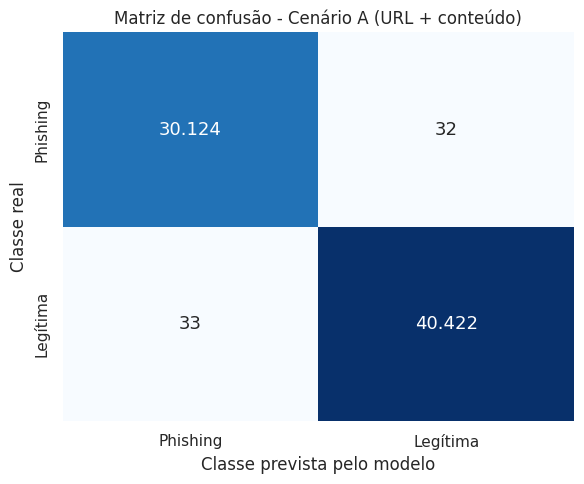

phishing que escaparam (classificados como legítimos): 32
legítimos marcados como phishing (alarme falso): 33


In [27]:
from sklearn.metrics import confusion_matrix

# linhas = classe real, colunas = classe prevista (ordem: phishing, legítima)
matriz_A = confusion_matrix(y_teste, previsao_A, labels=[0, 1])

# números no formato brasileiro (70.611 em vez de 70,611)
textos = [[f'{v:,}'.replace(',', '.') for v in linha] for linha in matriz_A]

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(matriz_A, annot=textos, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Phishing', 'Legítima'], yticklabels=['Phishing', 'Legítima'],
            annot_kws={'size': 13}, ax=ax)
ax.set_xlabel('Classe prevista pelo modelo')
ax.set_ylabel('Classe real')
ax.set_title('Matriz de confusão - Cenário A (URL + conteúdo)')
plt.tight_layout()
plt.savefig(os.path.join(PASTA, 'figuras/03_matriz_confusao_cenario_A.png'), dpi=300)
plt.show()

# destacando o erro mais grave
print('phishing que escaparam (classificados como legítimos):', matriz_A[0, 1])
print('legítimos marcados como phishing (alarme falso):', matriz_A[1, 0])

In [28]:
# guardando os resultados do cenário A pra comparar depois com o B
resultados = {}
resultados['Cenário A (URL + conteúdo)'] = {
    'acurácia': accuracy_score(y_teste, previsao_A),
    'precisão (phishing)': precision_score(y_teste, previsao_A, pos_label=0),
    'recall (phishing)': recall_score(y_teste, previsao_A, pos_label=0),
    'f1 (phishing)': f1_score(y_teste, previsao_A, pos_label=0),
    'phishing que escaparam': int(matriz_A[0, 1]),
}
pd.Series(resultados['Cenário A (URL + conteúdo)'])

,0
acurácia,0.999079
precisão (phishing),0.998906
recall (phishing),0.998939
f1 (phishing),0.998922
phishing que escaparam,32.000000


### Leitura dos resultados do Cenário A

Com as variáveis da URL e do conteúdo da página, o modelo alcançou acurácia de 99,91% no conjunto de teste. Das 30.156 URLs de phishing, 30.124 foram identificadas corretamente, o que corresponde a um recall de 99,89%. Apenas 32 golpes foram classificados como sites legítimos, e 33 sites legítimos foram marcados como phishing.

Na validação cruzada, as cinco rodadas apresentaram resultados praticamente iguais (desvio padrão entre 0,0001 e 0,0002), indicando que o desempenho é estável e não depende da divisão dos dados.

O desempenho próximo de 100% era esperado, pois a análise exploratória mostrou que as variáveis do conteúdo da página, como LineOfCode e NoOfExternalRef, já separam as classes quase perfeitamente quando consideradas isoladamente (AUC acima de 0,95). Esse resultado funciona como referência máxima para o Cenário B, que utiliza apenas o endereço.

##5. Cenário B

Neste cenário, o modelo utiliza apenas as 14 variáveis da URL, ou seja, somente características que podem ser calculadas a partir do endereço, sem abrir a página. É o cenário que responde à pergunta principal do projeto.

Os procedimentos são os mesmos do Cenário A, com a mesma divisão entre treino e teste. A única diferença está nas variáveis utilizadas.

In [29]:
# colunas do cenário B: só url
colunas_B = variaveis_url

# mesmo modelo do cenário A
modelo_B = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

# validação cruzada com as mesmas 5 partes e as mesmas métricas
cv_B = cross_validate(modelo_B, X_treino[colunas_B], y_treino, cv=folds, scoring=metricas)

tabela_cv_B = pd.DataFrame({
    'média': [cv_B['test_' + m].mean() for m in metricas],
    'desvio': [cv_B['test_' + m].std() for m in metricas],
}, index=list(metricas)).round(4)
tabela_cv_B

,média,desvio
acurácia,0.9800,0.0010
precisão (phishing),0.9878,0.0006
recall (phishing),0.9651,0.0019
f1 (phishing),0.9764,0.0012


In [30]:
# treinando com o treino inteiro e avaliando no teste
modelo_B.fit(X_treino[colunas_B], y_treino)
previsao_B = modelo_B.predict(X_teste[colunas_B])

print(classification_report(y_teste, previsao_B,
                            target_names=['phishing (0)', 'legítima (1)'], digits=4))

              precision    recall  f1-score   support

phishing (0)     0.9884    0.9710    0.9796     30156
legítima (1)     0.9787    0.9915    0.9850     40455

    accuracy                         0.9827     70611
   macro avg     0.9835    0.9812    0.9823     70611
weighted avg     0.9828    0.9827    0.9827     70611



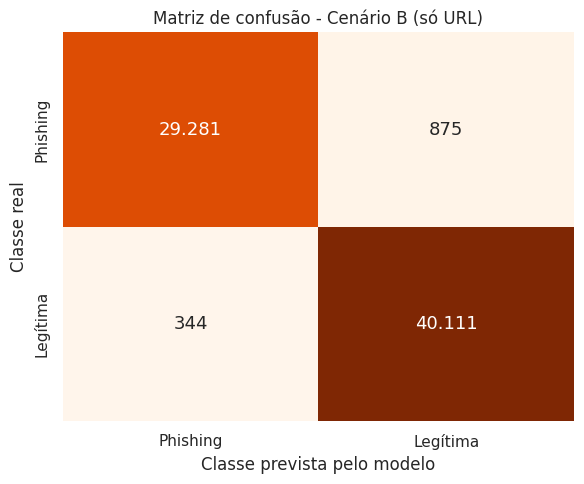

phishing que escaparam (classificados como legítimos): 875
legítimos marcados como phishing (alarme falso): 344


In [31]:
# matriz de confusão do cenário B
matriz_B = confusion_matrix(y_teste, previsao_B, labels=[0, 1])
textos = [[f'{v:,}'.replace(',', '.') for v in linha] for linha in matriz_B]

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(matriz_B, annot=textos, fmt='', cmap='Oranges', cbar=False,
            xticklabels=['Phishing', 'Legítima'], yticklabels=['Phishing', 'Legítima'],
            annot_kws={'size': 13}, ax=ax)
ax.set_xlabel('Classe prevista pelo modelo')
ax.set_ylabel('Classe real')
ax.set_title('Matriz de confusão - Cenário B (só URL)')
plt.tight_layout()
plt.savefig(os.path.join(PASTA, 'figuras/04_matriz_confusao_cenario_B.png'), dpi=300)
plt.show()

print('phishing que escaparam (classificados como legítimos):', matriz_B[0, 1])
print('legítimos marcados como phishing (alarme falso):', matriz_B[1, 0])

In [32]:
# guardando os resultados do cenário B
resultados['Cenário B (só URL)'] = {
    'acurácia': accuracy_score(y_teste, previsao_B),
    'precisão (phishing)': precision_score(y_teste, previsao_B, pos_label=0),
    'recall (phishing)': recall_score(y_teste, previsao_B, pos_label=0),
    'f1 (phishing)': f1_score(y_teste, previsao_B, pos_label=0),
    'phishing que escaparam': int(matriz_B[0, 1]),
}

# tabela comparando os dois cenários
comparacao = pd.DataFrame(resultados).T
comparacao.to_csv(os.path.join(PASTA, 'dados/processados/comparacao_cenarios.csv'))
comparacao.round(4)

,acurácia,precisão (phishing),recall (phishing),f1 (phishing),phishing que escaparam
Cenário A (URL + conteúdo),0.9991,0.9989,0.9989,0.9989,32.0
Cenário B (só URL),0.9827,0.9884,0.9710,0.9796,875.0


### Leitura dos resultados do Cenário B

Utilizando apenas as 14 variáveis da URL, o modelo alcançou acurácia de 98,27% no conjunto de teste. Das 30.156 URLs de phishing, 29.281 foram identificadas corretamente, o que corresponde a um recall de 97,10%. Foram 875 golpes classificados como legítimos e 344 sites legítimos marcados como phishing.

Na validação cruzada, o desvio padrão ficou entre 0,0006 e 0,0019, mostrando que o desempenho também é estável neste cenário.

##6. Comparação e importância

### Comparação entre os cenários

A retirada das variáveis do conteúdo da página reduziu a acurácia em 1,64 ponto percentual e o recall de phishing em 2,79 pontos percentuais. Em termos relativos, a perda é moderada: o modelo baseado apenas no endereço continua identificando cerca de 97 em cada 100 golpes. Em números absolutos, porém, a quantidade de phishing não detectado passou de 32 para 875, um aumento de aproximadamente 27 vezes.

O desempenho do Cenário B deve ser interpretado com cautela. Na base PhiUSIIL, as URLs legítimas aparecem predominantemente como endereços de páginas iniciais (por exemplo, https://www.site.com), enquanto as URLs de phishing tendem a apresentar caminhos mais longos, com números e caracteres especiais. Assim, parte do desempenho pode refletir essa diferença de formato entre as classes, e não apenas características típicas de golpes. Essa limitação motiva o teste com URLs brasileiras recentes, apresentado na seção 7, que avalia se o modelo mantém o desempenho fora da base em que foi treinado.

### Importância das variáveis no Cenário B

Uma vantagem da Regressão Logística é a interpretabilidade: cada variável recebe um coeficiente que indica a direção e a intensidade da sua influência na decisão do modelo. Como as variáveis foram padronizadas, os coeficientes podem ser comparados entre si e representam o efeito do aumento de um desvio padrão em cada variável.

Os coeficientes foram apresentados em relação à classe phishing:

- **coeficiente positivo:** valores mais altos da variável aumentam a chance de a URL ser classificada como phishing;
- **coeficiente negativo:** valores mais altos da variável aumentam a chance de a URL ser classificada como legítima.

A razão de chances (*odds ratio*) indica quantas vezes a chance de phishing é multiplicada quando a variável aumenta um desvio padrão. Valores acima de 1 aumentam essa chance, e valores abaixo de 1 a reduzem.

In [33]:
# pegando a regressão logística de dentro do pipeline do cenário B
reg_B = modelo_B.named_steps['logisticregression']

# o modelo calcula a chance de ser legítima (classe 1),
# então inverto o sinal pra ler como chance de ser phishing
coef_phishing = -reg_B.coef_[0]

# montando a tabela: coeficiente e razão de chances (odds ratio) de cada variável
importancia = pd.DataFrame({
    'variável': colunas_B,
    'coeficiente (phishing)': coef_phishing,
    'razão de chances (phishing)': np.exp(coef_phishing),
}).sort_values('coeficiente (phishing)', ascending=False).reset_index(drop=True)

# salvando pra usar no artigo
importancia.to_csv(os.path.join(PASTA, 'dados/processados/coeficientes_cenario_B.csv'), index=False)
importancia.round(3)

,variável,coeficiente (phishing),razão de chances (phishing)
0,URLLength,49.436,2.948606e+21
1,NoOfOtherSpecialCharsInURL,15.150,3.796163e+06
2,NoOfQMarkInURL,2.611,1.361200e+01
3,DegitRatioInURL,1.762,5.825000e+00
4,CharContinuationRate,0.945,2.573000e+00
5,TLDLength,0.321,1.378000e+00
6,SpacialCharRatioInURL,0.200,1.221000e+00
7,HasObfuscation,-0.118,8.890000e-01
8,NoOfObfuscatedChar,-0.214,8.070000e-01
9,IsDomainIP,-0.445,6.410000e-01


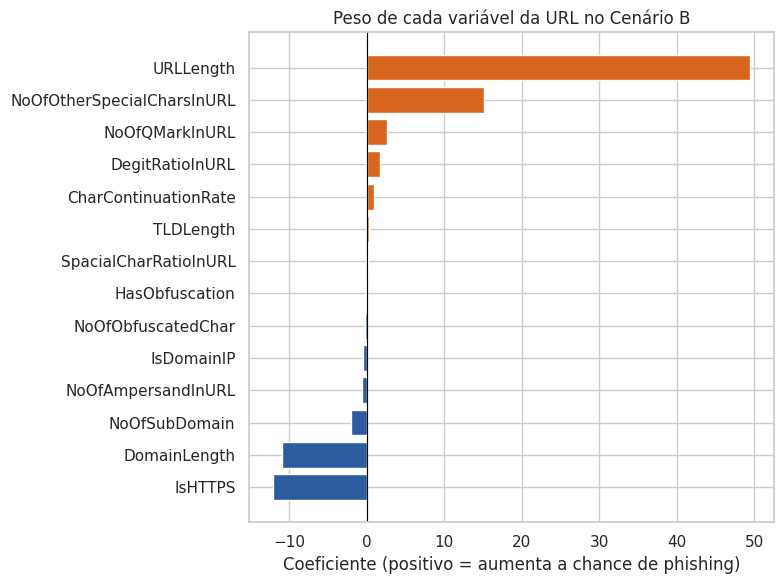

In [34]:
# ordenando do menor pro maior pra o gráfico ficar organizado
ordem = importancia.sort_values('coeficiente (phishing)')

# laranja = aumenta a chance de phishing, azul = aumenta a chance de legítima
cores = [CORES[0] if v > 0 else CORES[1] for v in ordem['coeficiente (phishing)']]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(ordem['variável'], ordem['coeficiente (phishing)'], color=cores)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Coeficiente (positivo = aumenta a chance de phishing)')
ax.set_title('Peso de cada variável da URL no Cenário B')
plt.tight_layout()
plt.savefig(os.path.join(PASTA, 'figuras/06_coeficientes_cenario_B.png'), dpi=300)
plt.show()

### Leitura da importância das variáveis

As variáveis que mais aumentam a chance de uma URL ser classificada como phishing são o tamanho da URL (URLLength), a quantidade de caracteres especiais (NoOfOtherSpecialCharsInURL), a presença do ponto de interrogação (NoOfQMarkInURL) e a proporção de dígitos (DegitRatioInURL). No sentido oposto, o uso de HTTPS (IsHTTPS), o tamanho do domínio (DomainLength) e a quantidade de subdomínios (NoOfSubDomain) aumentam a chance de classificação como legítima.

Os coeficientes de URLLength e DomainLength têm sinais opostos e magnitudes elevadas, o que indica que o modelo utiliza, na prática, a diferença entre os dois: o tamanho do trecho que vem depois do domínio, como caminhos e parâmetros. Como essas variáveis são relacionadas e as classes são fortemente separáveis na base, os valores absolutos dos coeficientes ficam inflados. Por isso, a análise considera apenas o sinal e a ordem de importância das variáveis, e não a magnitude das razões de chances.

Esse padrão explica os golpes brasileiros não detectados na seção 7: eles apresentam URLs curtas, sem caminho, com HTTPS e com domínios longos que incorporam o nome de marcas, ou seja, exatamente as características que o modelo associa a sites legítimos.

## 7. Validação com URLs brasileiras

Esta seção avalia se o modelo do Cenário B, treinado com a base internacional PhiUSIIL, mantém o desempenho quando aplicado a golpes direcionados ao público brasileiro. O modelo não é treinado novamente: ele apenas classifica URLs que nunca viu, coletadas em fontes diferentes da base original.

As URLs de phishing foram obtidas no PhishTank, repositório colaborativo que publica endereços de phishing denunciados e verificados por usuários. Cada registro informa a URL, a data da denúncia e, quando conhecida, a marca imitada pelo golpe. As páginas fraudulentas não são acessadas em nenhum momento: apenas o texto do endereço é utilizado para calcular as variáveis.

In [35]:
import requests

# data fixa da coleta: o phishtank muda todo dia, então o teste usa sempre a lista deste dia
# (assim o resultado se repete toda vez que o notebook rodar)
DATA_COLETA = '2026-10-19'
hoje = DATA_COLETA   # mantém o nome usado nas células seguintes

caminho_phishtank = os.path.join(PASTA, f'dados/urls_brasileiras/phishtank_{DATA_COLETA}.csv')

# só baixa se a lista dessa data ainda não estiver no drive
if os.path.exists(caminho_phishtank):
    print('usando a lista já salva, coletada em', DATA_COLETA)
else:
    cabecalho = {'User-Agent': 'phishtank/pi5-fatec-pesquisa'}
    resposta = requests.get('http://data.phishtank.com/data/online-valid.csv',
                            headers=cabecalho, timeout=120)
    print('status do download:', resposta.status_code)
    if resposta.status_code == 200:
        with open(caminho_phishtank, 'wb') as arquivo:
            arquivo.write(resposta.content)
        print('arquivo salvo em:', caminho_phishtank)

usando a lista já salva, coletada em 2026-10-19


In [36]:
# lendo a lista baixada
phishtank = pd.read_csv(caminho_phishtank)

print('total de urls na lista:', len(phishtank))
print('colunas:', phishtank.columns.tolist())

# período coberto pelas denúncias
phishtank['submission_time'] = pd.to_datetime(phishtank['submission_time'], errors='coerce')
print('primeira denúncia:', phishtank['submission_time'].min())
print('última denúncia:', phishtank['submission_time'].max())

# marcas mais imitadas na lista toda
phishtank['target'].value_counts().head(30)

total de urls na lista: 60372
colunas: ['phish_id', 'url', 'phish_detail_url', 'submission_time', 'verified', 'verification_time', 'online', 'target']
primeira denúncia: 2011-02-18 10:50:32+00:00
última denúncia: 2026-10-19 19:11:34+00:00


,count
target,
Other,53628
Allegro,2803
Internal Revenue Service,820
Amazon.com,569
Facebook,397
Microsoft,336
Netflix,174
Bradesco,159
Optus,135


### Seleção das URLs direcionadas ao público brasileiro

Uma URL foi considerada direcionada ao público brasileiro quando atendia a pelo menos um dos critérios:

1. a marca imitada (campo *target*) corresponde a uma empresa ou serviço brasileiro;
2. o próprio endereço contém o nome de marcas ou serviços brasileiros, como bancos, Correios, Pix, Receita Federal ou Detran;
3. o domínio termina em `.br`.

Após o filtro, uma amostra das URLs selecionadas foi conferida manualmente, apenas pela leitura do endereço, para descartar falsos positivos.

In [37]:
import re

# marcas e serviços brasileiros mais imitados em golpes
marcas_br = ['banco do brasil', 'caixa', 'itau', 'itaú', 'bradesco', 'nubank',
             'mercado livre', 'mercadolivre', 'mercado pago', 'mercadopago',
             'correios', 'banco inter', 'sicoob', 'sicredi', 'magazine luiza', 'magalu',
             'americanas', 'casas bahia', 'serasa', 'receita federal', 'detran',
             'gov.br', 'brasil', 'brazil']

# junto tudo num padrão só; o pix vai com \b pra não pegar 'pixel'
padrao = '|'.join(re.escape(m) for m in marcas_br) + r'|\bpix\b'

# critério 1: a marca imitada é brasileira
alvo_br = phishtank['target'].str.lower().str.contains(padrao, na=False, regex=True)

# critério 2: o endereço cita marca ou serviço brasileiro
url_br = phishtank['url'].str.lower().str.contains(padrao, na=False, regex=True)

# critério 3: o domínio termina em .br
dominio = phishtank['url'].str.lower().str.extract(r'^[a-z]+://([^/:?#]+)')[0]
dominio_br = dominio.str.endswith('.br', na=False)

# fica a url que atende pelo menos um critério
phishing_br = phishtank[alvo_br | url_br | dominio_br].copy()

print('urls brasileiras encontradas:', len(phishing_br))
print('pelo alvo:', alvo_br.sum(), '| pelo endereço:', url_br.sum(), '| por .br:', dominio_br.sum())

# salvando a seleção
phishing_br.to_csv(os.path.join(PASTA, f'dados/urls_brasileiras/phishing_br_{hoje}.csv'), index=False)

# mostrando 20 exemplos pra conferir na leitura (não clique nos links!)
pd.set_option('display.max_colwidth', 120)
phishing_br[['url', 'target', 'submission_time']].sample(min(20, len(phishing_br)), random_state=42)

urls brasileiras encontradas: 564
pelo alvo: 172 | pelo endereço: 277 | por .br: 189


,url,target,submission_time
57767,http://officialpaper.com.br/,Other,2023-04-09 20:37:17+00:00
56196,https://brwsuprimentos.com.br/,Other,2023-07-09 05:16:23+00:00
15147,https://bradesco.suporteredejuridico.click,Other,2026-05-28 03:19:08+00:00
56290,https://bancopanrefin.multidadosti.com.br/,Other,2023-07-05 14:44:45+00:00
48426,http://emailmarketing.locaweb.com.br/accounts/122532/messages/919/openings/37004?envelope_id=840,Other,2024-05-20 15:59:42+00:00
18593,https://bradesco.chatnetempresas.info/inicio,Other,2026-04-21 02:48:54+00:00
15412,https://bradesco.atualizarmodulo.com/boasvindas.php?token=4311714086a1465135436a6.19879758&amp;h=676aad09c07157d94c2...,Other,2026-05-25 18:10:10+00:00
49262,https://qrco.de/bey9Hj?https://itau.com.br,Adobe,2024-04-16 12:13:51+00:00
25008,https://editorazoreba.com.br/neew/axa/axa/login.php,Other,2026-01-28 08:08:57+00:00
14644,https://bradesco.pjempresascorp.digital,Bradesco,2026-06-01 13:55:17+00:00


### Refinamento da seleção

A primeira seleção incluiu URLs denunciadas entre 2023 e 2026 e alguns golpes hospedados em domínios brasileiros, mas direcionados a marcas estrangeiras. Para manter o foco em golpes recentes voltados ao público brasileiro, foram mantidas apenas as URLs:

1. denunciadas a partir de 1º de janeiro de 2024, período posterior à coleta da base PhiUSIIL;
2. cuja marca imitada é brasileira ou não foi identificada (*Other*), excluindo golpes direcionados a marcas estrangeiras.

Também foram removidas URLs repetidas e URLs que já constavam na base PhiUSIIL, garantindo que o teste seja feito apenas com endereços que o modelo nunca viu.

In [38]:
# vendo quais alvos apareceram na seleção, pra decidir o que é estrangeiro
print(phishing_br['target'].value_counts().head(30))

# critério de data: só denúncias a partir de 2024 (depois da coleta da phiusiil)
recente = phishing_br['submission_time'] >= '2024-01-01'

# critério de alvo: marca brasileira ou alvo não identificado ('Other')
alvo_ok = phishing_br['target'].str.lower().str.contains(padrao, na=False, regex=True) | \
          (phishing_br['target'] == 'Other')

phishing_final = phishing_br[recente & alvo_ok].copy()

# tirando urls repetidas
phishing_final = phishing_final.drop_duplicates(subset='url')

# tirando urls que já estavam na base phiusiil (o modelo não pode ter visto)
urls_treino = pd.read_csv(os.path.join(PASTA, 'dados/processados/urls_referencia.csv'))['URL']
ja_vistas = phishing_final['url'].isin(urls_treino)
print('\nurls que já estavam na phiusiil:', ja_vistas.sum())
phishing_final = phishing_final[~ja_vistas]

print('urls de phishing brasileiras após o refinamento:', len(phishing_final))
print('período:', phishing_final['submission_time'].min(), 'até', phishing_final['submission_time'].max())

# salvando a versão final
phishing_final.to_csv(os.path.join(PASTA, f'dados/urls_brasileiras/phishing_br_final_{hoje}.csv'), index=False)

target
Other                             356
Bradesco                          159
Internal Revenue Service            8
Banco De Brasil                     7
Adobe                               6
ABSA Bank                           4
DocuSign                            3
Itau                                2
Bank of America Corporation         2
Hotmail                             2
PayPal                              2
Caixa                               2
Netflix                             1
WeTransfer                          1
Swiss Post                          1
American Express                    1
The Brazilian Development Bank      1
Facebook                            1
Microsoft                           1
ABN AMRO Bank                       1
Nubank                              1
Accurint                            1
DHL                                 1
Name: count, dtype: int64

urls que já estavam na phiusiil: 0
urls de phishing brasileiras após o refinamento: 475
perí

### Seleção das URLs legítimas brasileiras

As URLs legítimas foram obtidas a partir das páginas iniciais dos domínios brasileiros (.br) mais acessados, segundo a lista Tranco, ranking público de popularidade de sites utilizado em pesquisas acadêmicas. Foi selecionada a mesma quantidade de URLs de phishing (475), mantendo as classes equilibradas.

Como o foco do estudo é a detecção de golpes, a análise principal concentra-se no recall da classe phishing. A avaliação de alarmes falsos em páginas internas de sites legítimos, cujos endereços são mais longos e complexos, não foi realizada e é apontada como limitação.

In [39]:
import zipfile, io

caminho_tranco = os.path.join(PASTA, f'dados/urls_brasileiras/tranco_{DATA_COLETA}.csv')

# só baixa se a lista dessa data ainda não estiver no drive
if os.path.exists(caminho_tranco):
    tranco = pd.read_csv(caminho_tranco)
    print('usando a lista tranco já salva, coletada em', DATA_COLETA)
else:
    resposta = requests.get('https://tranco-list.eu/top-1m.csv.zip', timeout=300)
    print('status do download:', resposta.status_code)
    with zipfile.ZipFile(io.BytesIO(resposta.content)) as z:
        tranco = pd.read_csv(z.open(z.namelist()[0]), header=None, names=['posicao', 'dominio'])
    tranco.to_csv(caminho_tranco, index=False)

# ficando só com os domínios brasileiros
tranco_br = tranco[tranco['dominio'].str.endswith('.br')]
print('domínios .br na lista:', len(tranco_br))

# pegando os mais acessados, na mesma quantidade das urls de phishing
legitimas_inicio = tranco_br.head(len(phishing_final)).copy()

# montando a url no formato da phiusiil; tiro o 'www.' que alguns já têm pra não duplicar
legitimas_inicio['url'] = 'https://www.' + legitimas_inicio['dominio'].str.replace(r'^www\.', '', regex=True)
legitimas_inicio['grupo'] = 'página inicial'
print('urls com www duplicado:', legitimas_inicio['url'].str.contains('www.www.', regex=False).sum())

# salvando já corrigido
legitimas_inicio.to_csv(os.path.join(PASTA, f'dados/urls_brasileiras/legitimas_inicio_{DATA_COLETA}.csv'), index=False)
legitimas_inicio.head(10)

usando a lista tranco já salva, coletada em 2026-10-19
domínios .br na lista: 17271
urls com www duplicado: 0


,posicao,dominio,url,grupo
532,533,uol.com.br,https://www.uol.com.br,página inicial
718,719,hostgator.com.br,https://www.hostgator.com.br,página inicial
767,768,shopee.com.br,https://www.shopee.com.br,página inicial
782,783,google.com.br,https://www.google.com.br,página inicial
856,857,amazon.com.br,https://www.amazon.com.br,página inicial
872,873,www.gov.br,https://www.gov.br,página inicial
927,928,mercadolivre.com.br,https://www.mercadolivre.com.br,página inicial
994,995,caixa.gov.br,https://www.caixa.gov.br,página inicial
1092,1093,olx.com.br,https://www.olx.com.br,página inicial
1094,1095,terra.com.br,https://www.terra.com.br,página inicial


### Cálculo das variáveis das URLs brasileiras

As variáveis das URLs brasileiras são calculadas com a mesma função utilizada no recálculo da base de treino (seção 3). Dessa forma, o modelo recebe valores medidos exatamente com a mesma regra usada no seu treinamento. O cálculo utiliza apenas o texto do endereço: nenhuma página é acessada.

Em seguida, o modelo do Cenário B é aplicado às 950 URLs brasileiras (475 de phishing e 475 páginas iniciais de sites legítimos) sem novo treinamento, ou seja, utilizando exatamente o modelo ajustado com a base PhiUSIIL. Para cada URL, são registradas a classe prevista e a probabilidade estimada de ser phishing.

In [40]:
# juntando as urls brasileiras: phishing (0) e páginas iniciais legítimas (1)
teste_br = pd.concat([
    pd.DataFrame({'url': phishing_final['url'].values, 'label': 0, 'grupo': 'phishing'}),
    pd.DataFrame({'url': legitimas_inicio['url'].values, 'label': 1, 'grupo': 'página inicial'}),
], ignore_index=True)

# calculando as variáveis com a mesma função usada no treino
variaveis_br = pd.DataFrame([extrair_variaveis(u) for u in teste_br['url']])
teste_br = pd.concat([teste_br, variaveis_br[colunas_B]], axis=1)

# aplicando o modelo do cenário B, sem treinar de novo
teste_br['previsto'] = modelo_B.predict(teste_br[colunas_B])
# probabilidade de ser phishing (coluna 0, porque a classe 0 é phishing)
teste_br['prob_phishing'] = modelo_B.predict_proba(teste_br[colunas_B])[:, 0]

print('urls no teste brasileiro:', len(teste_br))
print(teste_br['grupo'].value_counts())

# relatório com precisão, recall e f1 de cada classe
print(classification_report(teste_br['label'], teste_br['previsto'],
                            target_names=['phishing (0)', 'legítima (1)'], digits=4))

# salvando pra consulta
teste_br.to_csv(os.path.join(PASTA, f'dados/urls_brasileiras/teste_br_resultado_{DATA_COLETA}.csv'), index=False)

urls no teste brasileiro: 950
grupo
phishing          475
página inicial    475
Name: count, dtype: int64
              precision    recall  f1-score   support

phishing (0)     1.0000    0.8358    0.9106       475
legítima (1)     0.8590    1.0000    0.9241       475

    accuracy                         0.9179       950
   macro avg     0.9295    0.9179    0.9173       950
weighted avg     0.9295    0.9179    0.9173       950



### Desempenho nas URLs brasileiras

A matriz de confusão e as métricas a seguir mostram o desempenho do modelo nas URLs brasileiras. Os resultados são apresentados ao lado dos obtidos no conjunto de teste da base PhiUSIIL, permitindo verificar se o modelo mantém o desempenho fora da base em que foi treinado, o que responde à pergunta complementar do estudo.


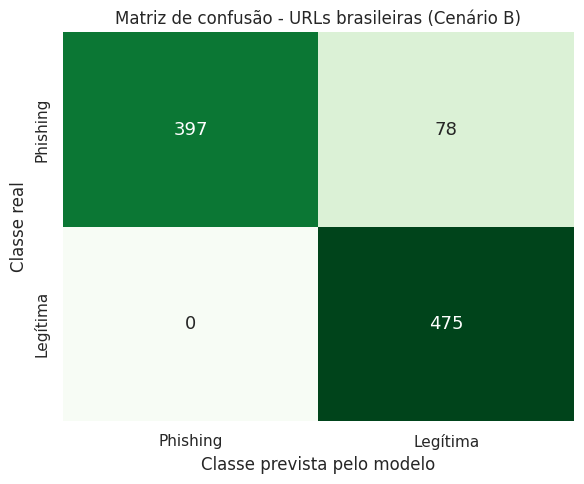

golpes brasileiros que escaparam: 78 de 475
sites legítimos marcados como phishing: 0 de 475


,acurácia,precisão (phishing),recall (phishing),f1 (phishing),phishing que escaparam
Cenário A (URL + conteúdo),0.9991,0.9989,0.9989,0.9989,32.0
Cenário B (só URL),0.9827,0.9884,0.9710,0.9796,875.0
Teste brasileiro (Cenário B),0.9179,1.0000,0.8358,0.9106,78.0


In [41]:
# matriz de confusão do teste brasileiro
matriz_br = confusion_matrix(teste_br['label'], teste_br['previsto'], labels=[0, 1])
textos = [[f'{v:,}'.replace(',', '.') for v in linha] for linha in matriz_br]

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(matriz_br, annot=textos, fmt='', cmap='Greens', cbar=False,
            xticklabels=['Phishing', 'Legítima'], yticklabels=['Phishing', 'Legítima'],
            annot_kws={'size': 13}, ax=ax)
ax.set_xlabel('Classe prevista pelo modelo')
ax.set_ylabel('Classe real')
ax.set_title('Matriz de confusão - URLs brasileiras (Cenário B)')
plt.tight_layout()
plt.savefig(os.path.join(PASTA, 'figuras/05_matriz_confusao_urls_brasileiras.png'), dpi=300)
plt.show()

print('golpes brasileiros que escaparam:', matriz_br[0, 1], 'de', matriz_br[0].sum())
print('sites legítimos marcados como phishing:', matriz_br[1, 0], 'de', matriz_br[1].sum())

# guardando junto com os resultados dos cenários
resultados['Teste brasileiro (Cenário B)'] = {
    'acurácia': accuracy_score(teste_br['label'], teste_br['previsto']),
    'precisão (phishing)': precision_score(teste_br['label'], teste_br['previsto'], pos_label=0),
    'recall (phishing)': recall_score(teste_br['label'], teste_br['previsto'], pos_label=0),
    'f1 (phishing)': f1_score(teste_br['label'], teste_br['previsto'], pos_label=0),
    'phishing que escaparam': int(matriz_br[0, 1]),
}

# tabela final: base original x urls brasileiras
comparacao_final = pd.DataFrame(resultados).T
comparacao_final.to_csv(os.path.join(PASTA, 'dados/processados/comparacao_final.csv'))
comparacao_final.round(4)

### Leitura dos resultados com URLs brasileiras

Aplicado sem novo treinamento a 950 URLs brasileiras, o modelo do Cenário B alcançou acurácia de 91,79%. Das 475 URLs de phishing, 397 foram identificadas corretamente, o que corresponde a um recall de 83,58%, contra 97,10% no conjunto de teste da base PhiUSIIL. A proporção de golpes não detectados passou de 2,9% para 16,4%, uma queda de 13,5 pontos percentuais no recall.

Nenhuma das 475 páginas iniciais legítimas foi classificada como phishing. Esse resultado, no entanto, deve ser interpretado com cautela: as URLs legítimas utilizadas seguem o mesmo formato de página inicial predominante entre as legítimas da base de treino, o que torna sua identificação mais fácil. Endereços legítimos mais longos, como páginas de produtos ou de serviços, podem gerar alarmes falsos, o que não foi avaliado neste estudo e constitui uma limitação.

Esses resultados indicam que o modelo baseado apenas no endereço mantém capacidade de detecção em golpes brasileiros recentes, mas com desempenho inferior ao observado na base em que foi treinado, o que reforça a dependência das características em relação à base de dados utilizada.

In [42]:
# separando os golpes brasileiros que escaparam dos que foram pegos
golpes = teste_br[teste_br['label'] == 0].copy()
golpes['situacao'] = golpes['previsto'].map({0: 'detectado', 1: 'escapou'})

# juntando a marca imitada (target) que veio do phishtank
golpes['target'] = phishing_final['target'].values

# comparando as características médias dos dois grupos
print('média das variáveis: detectados x escaparam')
print(golpes.groupby('situacao')[['URLLength', 'NoOfOtherSpecialCharsInURL',
                                  'DegitRatioInURL', 'NoOfSubDomain', 'IsHTTPS']].mean().round(3).T)

# marcas mais comuns entre os que escaparam
print('\nmarcas imitadas pelos golpes que escaparam:')
print(golpes[golpes['situacao'] == 'escapou']['target'].value_counts().head(10))

# 15 exemplos dos que escaparam (só leitura, não clique!)
pd.set_option('display.max_colwidth', 100)
golpes[golpes['situacao'] == 'escapou'][['url', 'target', 'prob_phishing']].head(15)

média das variáveis: detectados x escaparam
situacao                    detectado  escapou
URLLength                      67.189   35.077
NoOfOtherSpecialCharsInURL      8.469    4.923
DegitRatioInURL                 0.047    0.002
NoOfSubDomain                   1.174    0.705
IsHTTPS                         0.902    1.000

marcas imitadas pelos golpes que escaparam:
target
Bradesco                          42
Other                             35
The Brazilian Development Bank     1
Name: count, dtype: int64


,url,target,prob_phishing
3,https://antivirusbradesco.com,Bradesco,0.033574
4,https://www.bradescosaudeplus.com.br,Other,0.019961
5,https://componentebradesco.vip,Other,0.038175
27,https://bradesco.acessopjcliente.com,Other,0.015314
29,https://seguronetempresapj.digital,Bradesco,0.177248
30,https://netempresasatualizar24horas.digital,Bradesco,0.466918
31,https://correiosapool0gin-correiopt.netlify.app,Other,0.409896
43,https://acessocorporativobradesco.digital,Other,0.353524
51,https://app.clientepresent.live,Bradesco,0.029701
58,https://Bradesco.apoiocorporativo.com,Other,0.017972


### Análise dos golpes não detectados

Os 78 golpes brasileiros não detectados apresentam características muito diferentes dos detectados. Em média, suas URLs têm 35 caracteres, contra 67 dos golpes identificados, menos caracteres especiais (4,9 contra 8,5), quase nenhum dígito (0,2% contra 4,7%), menos subdomínios (0,7 contra 1,2) e todas utilizam HTTPS. Ou seja, os golpes que escaparam têm o formato de páginas iniciais, o mesmo perfil que o modelo aprendeu a associar a sites legítimos na base PhiUSIIL.

A leitura dos endereços mostra que, nesses casos, a fraude está no próprio nome do domínio, e não na estrutura da URL: há domínios que incorporam o nome de uma marca (como "antivirusbradesco.com" e "acessocorporativobradesco.digital"), variações com erros de digitação ("itauu.vercel.app") e extensões pouco comuns (.digital, .vip, .click, .live). A maior parte desses golpes imita o Bradesco.

As variáveis utilizadas no modelo descrevem o formato da URL, mas não capturam o uso indevido de nomes de marcas nem a reputação da extensão do domínio. Essa limitação sugere, como trabalho futuro, a inclusão de variáveis que identifiquem nomes de marcas conhecidas em domínios que não pertencem a elas.

In [43]:
# salvando o modelo do cenário b para usar no app (deploy)
# o app não precisa do scikit-learn: basta guardar a padronização e os coeficientes,
# que são exatamente o que a regressão logística usa para decidir
import json, joblib, math

escalador = modelo_B.named_steps['standardscaler']
regressao = modelo_B.named_steps['logisticregression']

parametros = {
    'colunas': list(colunas_B),
    'media': escalador.mean_.tolist(),
    'desvio': escalador.scale_.tolist(),
    'coeficientes': regressao.coef_[0].tolist(),   # coeficientes da classe 1 (legítima)
    'intercepto': float(regressao.intercept_[0]),
}

caminho_json = os.path.join(PASTA, 'modelo_B_parametros.json')
with open(caminho_json, 'w', encoding='utf-8') as f:
    json.dump(parametros, f, ensure_ascii=False, indent=2)

# guardando também o pipeline inteiro, como artefato técnico do projeto
joblib.dump(modelo_B, os.path.join(PASTA, 'modelo_B.joblib'))

# conferindo: a conta "na mão" com o json tem que dar o mesmo resultado do modelo
def prob_phishing_json(url):
    v = extrair_variaveis(url)
    soma = parametros['intercepto']
    for col, m, d, c in zip(parametros['colunas'], parametros['media'],
                            parametros['desvio'], parametros['coeficientes']):
        soma += c * (v[col] - m) / d
    return 1 - 1 / (1 + math.exp(-soma))

for u in ['https://www.google.com', 'https://antivirusbradesco.com',
          'http://login-banco.atualiza-cadastro.xyz/conta/12345?id=99&tk=abc']:
    x = pd.DataFrame([extrair_variaveis(u)])[colunas_B]
    print(f'{u[:45]:45} | modelo: {modelo_B.predict_proba(x)[0, 0]:.4f} | json: {prob_phishing_json(u):.4f}')

print('\nsalvo em:', caminho_json)

https://www.google.com                        | modelo: 0.0042 | json: 0.0042
https://antivirusbradesco.com                 | modelo: 0.0336 | json: 0.0336
http://login-banco.atualiza-cadastro.xyz/cont | modelo: 1.0000 | json: 1.0000

salvo em: /content/drive/MyDrive/PI5_phishing/modelo_B_parametros.json
